# SmolVLA, step by step 🤏
### A small VLM that *perceives*, a thin flow-matching expert that *acts*, and an asynchronous stack that keeps the robot moving

**Model:** `SmolVLAPolicy` (`src/Halo_VLA/open_vlas/smolvla.py`) · **async stack:** `open_vlas/async_inference.py` · **paper:** M. Shukor, D. Aubakirova, F. Capuano et al.,
*SmolVLA: A Vision-Language-Action Model for Affordable and Efficient Robotics*, Hugging Face, 2025
([arXiv:2506.01844](https://arxiv.org/abs/2506.01844)) · **code:** [LeRobot](https://github.com/huggingface/lerobot)

Big VLAs (π0: 3.3B parameters, OpenVLA: 7B) need datacenter GPUs. SmolVLA asks: *how small and cheap can a VLA be and still work?* Its answer is a recipe
of **five efficiency choices**, each of which this notebook builds, checks and measures:

| # | choice | what it saves | step |
|---|---|---|---|
| 1 | **fewer visual tokens**: no image tiling, a *pixel shuffle* → 64 tokens per frame | sequence length (attention is quadratic) | 2 |
| 2 | **layer skipping**: the action expert reads the VLM's layers `1…N`, `N = L/2`; the top half of the VLM is deleted | half the VLM compute | 4 |
| 3 | **a thin action expert**, hidden size `0.75 ×` the VLM's, **interleaving cross-attention and causal self-attention** | expert compute, and smoother chunks | 5 |
| 4 | **a frozen VLM**: only the expert, the state projection and the feature projectors are trained | training cost | 6 |
| 5 | **asynchronous inference**: predict the next chunk while the current one is still executing | robot idle time, no extra hardware | 11 |

| | published SmolVLA | this notebook |
|---|---|---|
| VLM | SmolVLM-2 (SigLIP + SmolLM2), first 16 of 32 LLM layers | toy VLM (patch encoder + 6-layer transformer), first 3 layers |
| visual tokens | 64 per frame (pixel shuffle, no tiling) | 16 per frame (the same pixel shuffle) |
| action expert | ≈100M of 450M parameters, width 0.75×, flow matching, chunk n = 50, 10 denoising steps | width 0.75× (48), flow matching, chunk n = 16, 10 steps |
| pre-training | 481 community datasets, 22.9K episodes, 10.6M frames, 200K steps, batch 256 | 4000 scripted demonstrations, 3000 steps |
| evaluation | LIBERO, Meta-World, real SO-100 / SO-101 arms | closed loop in a 2-D point world |

> **How to read the results.** Everything is a toy: one seed, 96 unseen scenes per number. Differences of a few points are noise; large effects are real. Where our toy
> disagrees with the paper's ablation tables we say so instead of hiding it. Total runtime is about 20 minutes on a laptop CPU.

## Step 0: Setup and the data

The **point world** from the π-family notebooks: a 32×32 RGB image with 2-3 coloured squares and a white robot dot. The instruction is `"go to red | green | blue"`; the
action is a 2-D motion command, normalised so `|a| ≈ 1` is one full step (0.05 of the world width). SmolVLA predicts a **chunk** of `n` future actions at once and
executes (some of) them before looking again; here `n = 16`.

The state `q_t` is the robot's position. We use the shared `VLABatch` format of the `open_vlas` package: image, state (zero-padded to the largest embodiment), instruction,
action chunk, and an embodiment id (always `point2d` in this notebook).

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import vla_kit
vla_kit.setup_paths()
from vla_kit import plots, diagrams as dg

from open_vlas import (EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, SmolVLAConfig, SmolVLAPolicy, ToyVLM, VLMConfig,
                       VLMPretrainer, make_embodied_scenarios, make_reach_demos)
from open_vlas.async_inference import AsyncConfig, AsyncInferenceRunner, evaluate_async, make_policy_call
from open_vlas.attention import causal_mask
from pi_family import PiTrainer
from pi_family.toy import DemoGenerator, PointWorld

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
print("torch", torch.__version__)

torch 2.13.0


images (6, 3, 32, 32) = (B, 3, S, S)   state (6, 3) (zero-padded)   actions (6, 16, 4) = (B, n, action dim padded)


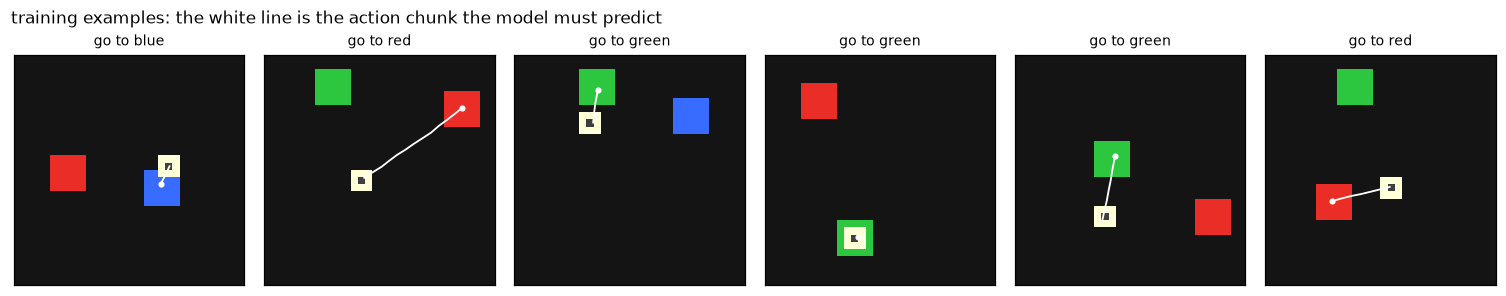

In [2]:
world = PointWorld()
gen = DemoGenerator(world)
demos = make_reach_demos(gen, 4000, np.random.default_rng(0))          # scripted expert demonstrations, targets red / green / blue
data = EmbodiedMixture([EmbodiedSource(world, demos, EMBODIMENTS["point2d"])])
batch = data.sample(6, np.random.default_rng(1))
print("images", tuple(batch.images.shape), "= (B, 3, S, S)   state", tuple(batch.state.shape), "(zero-padded)   actions", tuple(batch.actions.shape), "= (B, n, action dim padded)")
plots.show_batch(batch, title="training examples: the white line is the action chunk the model must predict")

### 🖼️ Diagram: the whole model

Blue = the frozen, truncated VLM. Red = the thin action expert. Every other expert block is a **cross-attention** that reads the VLM's hidden state *of the matching layer*
(dashed arrows); the blocks in between are **causal self-attention** over the action tokens. The VLM runs **once** per observation; the expert runs once per denoising step.

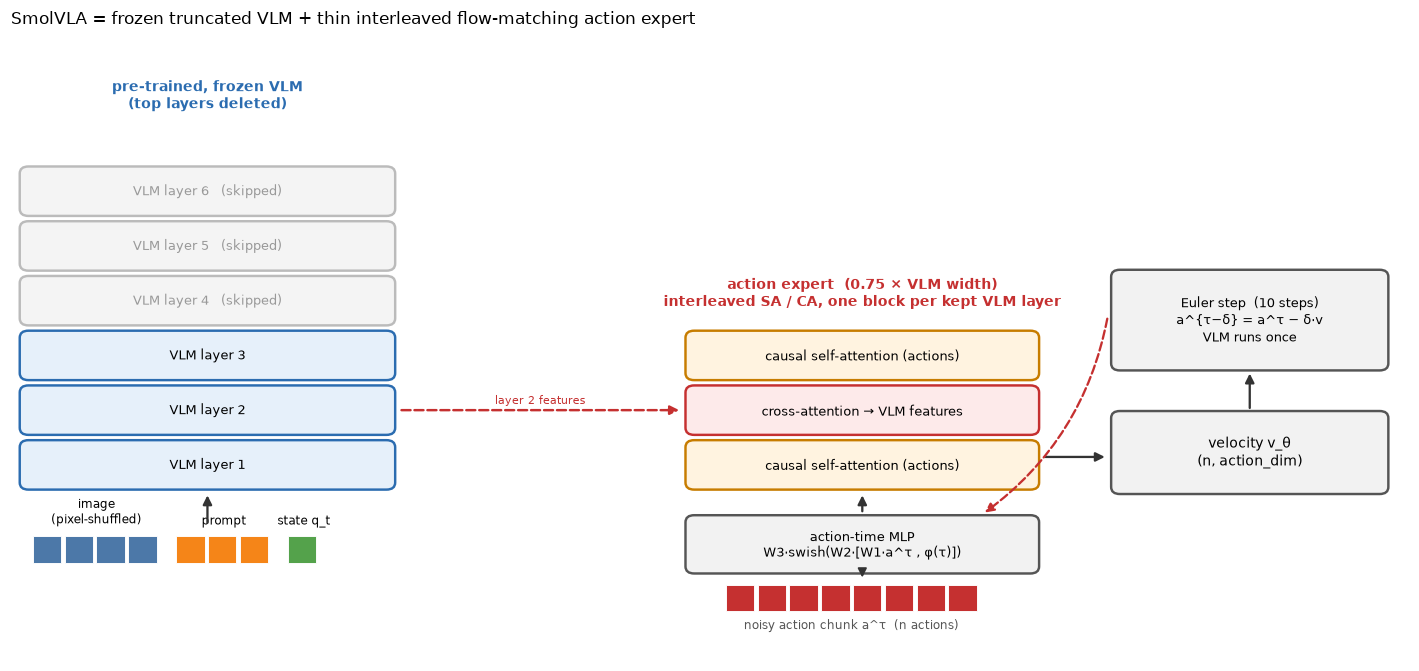

In [3]:
dg.fig_smolvla_architecture(layers=6, skip_to=3)

## Step 1: The VLM's job is perception, so pre-train it first

SmolVLA does not teach vision from scratch: it starts from **SmolVLM-2**, a VLM already trained on web-scale image-text data, and *freezes* it. Freezing is only sensible if the
VLM's features already encode what the robot needs, e.g. "where is the red thing?". Our toy VLM gets the equivalent head start from a minute of **visual question answering**
on point-world images (`VLMPretrainer`):

```
<image tokens> <bos> where is red <sep>   →   "70 30" <eos>            (x and y of the object, in tens of percent)
```

The answer tokens are causal, everything before them is one bidirectional block (a *prefix LM*, like PaliGemma and SmolVLM). Nothing robot-specific is in this stage: it only
produces a perceiving backbone.

VLM pre-training step   500  loss 0.626  token accuracy 0.78


VLM pre-training step  1000  loss 0.108  token accuracy 0.94


VLM pre-training step  1500  loss 0.146  token accuracy 0.91
VLM pre-training took 37 s, answer-token accuracy 0.93
{'parameters': '285,376', 'layers': 6, 'width': 64, 'visual tokens per frame': 16}


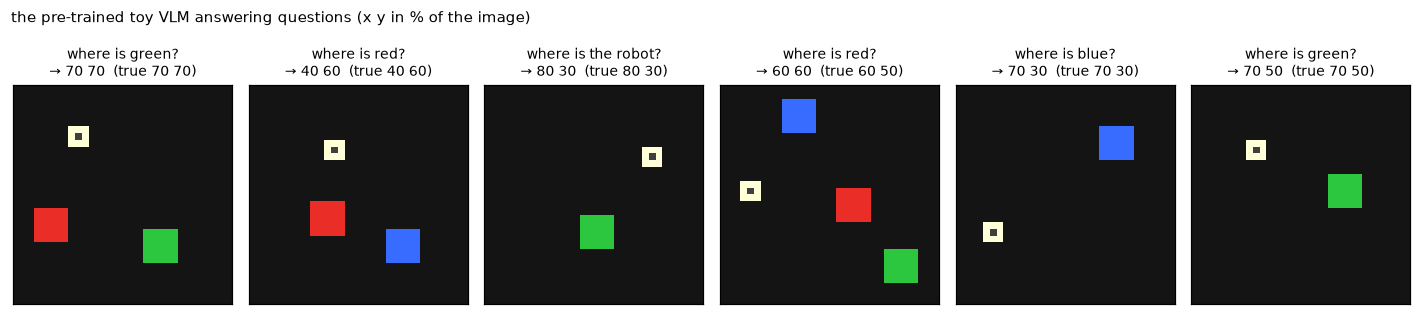

In [4]:
vlm = ToyVLM(VLMConfig())
pre = VLMPretrainer(vlm, world)
pre.fit(1500, log_every=500)
print(f"VLM pre-training took {pre.history.seconds:.0f} s, answer-token accuracy {np.mean(pre.history.accuracy[-50:]):.2f}")
print({"parameters": f"{sum(p.numel() for p in vlm.parameters()):,}", "layers": vlm.num_layers, "width": vlm.cfg.width, "visual tokens per frame": vlm.cfg.num_image_tokens})

imgs, qs, ans = pre.sample(6)
fig, axes = plt.subplots(1, 6, figsize=(13, 2.7))
for ax, img, q, a in zip(axes, imgs, qs, ans):
    plots.show_image(ax, img, f"{q.replace('the object', 'the robot')}?\n→ {pre.ask(img[None], q)[0]}  (true {a})")
plt.suptitle("the pre-trained toy VLM answering questions (x y in % of the image)", x=0.01, y=1.06, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

## Step 2: Fewer visual tokens: the pixel shuffle

Self-attention costs `O(T²)` in the sequence length `T`, and images are the longest part of the sequence. The usual VLM trick is **image tiling** (several crops plus a global
view), which *multiplies* the tokens. SmolVLA goes the other way: **no tiling, global image only, plus a pixel shuffle** (space-to-depth) that merges each `2×2` block of patch
tokens into **one** token of 4× the channels and projects it back. That caps SmolVLM-2 at **64 tokens per frame**; our 32×32 image has 8×8 = 64 patches, which the shuffle
reduces to **16** tokens. Nothing is thrown away (the 4 patches' features are concatenated), it is just a re-arrangement plus a linear layer.

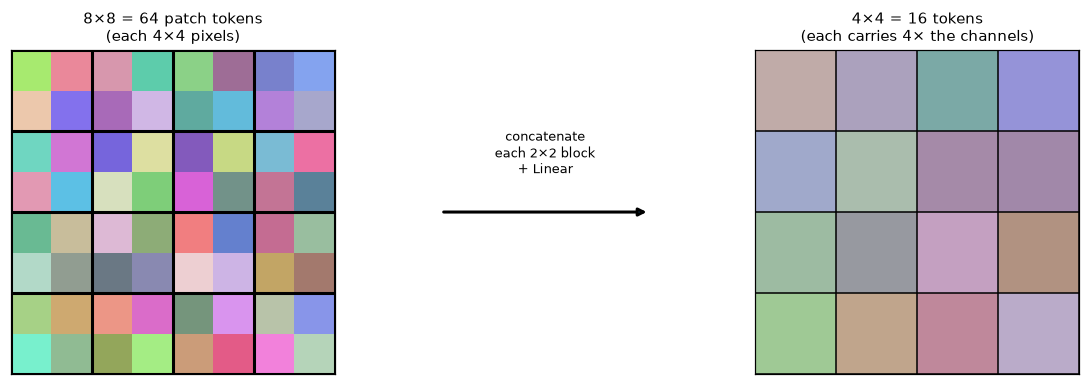

patch tokens: (2, 64, 64) → shuffled tokens: (2, 16, 64)
matches an explicit 2x2-block loop: True


In [5]:
dg.fig_pixel_shuffle(grid=8, shuffle=2)
enc = vlm.vision
img = imgs[:2]
with torch.no_grad():
    patches = enc.patch_tokens(img)                       # (B, 64, W) one token per 4x4 patch
    merged = enc(img)                                     # (B, 16, W) after the pixel shuffle
    grid = patches.view(2, 8, 8, -1)
    manual = torch.stack([enc.merge(grid[:, 2*i:2*i+2, 2*j:2*j+2].reshape(2, -1)) for i in range(4) for j in range(4)], 1)
print("patch tokens:", tuple(patches.shape), "→ shuffled tokens:", tuple(merged.shape))
print("matches an explicit 2x2-block loop:", torch.allclose(merged, manual, atol=1e-5))

What does that buy? The cost of a forward pass through the VLM with 64 vs 16 image tokens (same weights otherwise, random initialisation is enough to time it):

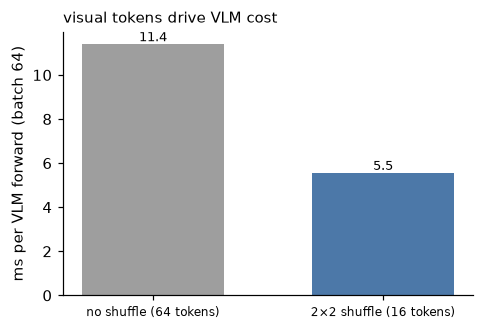

In [6]:
def time_vlm(shuffle, reps=15, batch=64):
    m = ToyVLM(VLMConfig(shuffle=shuffle)).eval()
    x = torch.rand(batch, 3, 32, 32)
    with torch.no_grad():
        m.forward_layers(m.build_inputs(x, ["go to red"] * batch)); t0 = time.perf_counter()
        for _ in range(reps):
            m.forward_layers(m.build_inputs(x, ["go to red"] * batch))
    return 1000 * (time.perf_counter() - t0) / reps, m.cfg.num_image_tokens

rows = {f"{'no shuffle' if s == 1 else '2×2 shuffle'} ({time_vlm(s)[1]} tokens)": time_vlm(s)[0] for s in (1, 2)}
plots.bar_compare(rows, "ms per VLM forward (batch 64)", "visual tokens drive VLM cost", fmt="{:.1f}", colors=["#9e9e9e", "#4c78a8"])

## Step 3: One sequence: image, words, and the robot state as a token

The VLM reads `[image tokens | prompt tokens | state token]`. The **state** `q_t` goes through a linear layer to the VLM's width and becomes **one token** in the prefix
(the paper's ablation, Table 11, finds this clearly better than giving the state to the action expert). All of it is a single bidirectional block: every token sees every other.

sequence: (6, 22, 64) = (B, 16 image + words + 1 state, width)


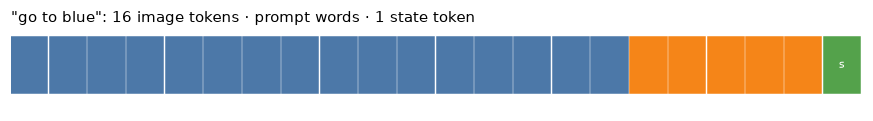

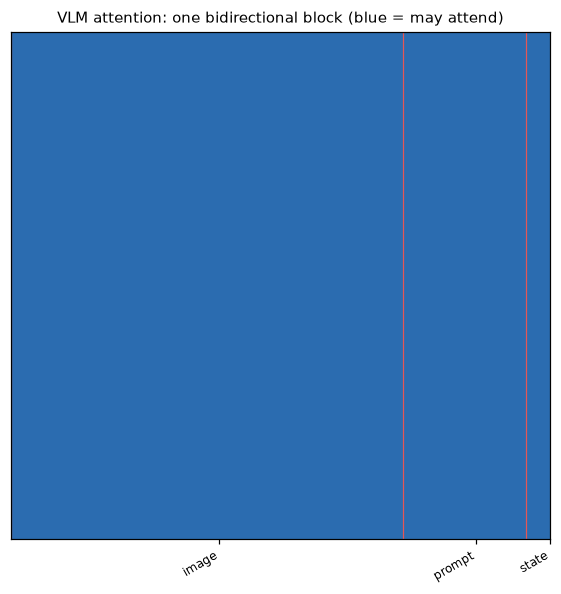

In [7]:
state_proj = torch.nn.Linear(2, vlm.cfg.width)
with torch.no_grad():
    inputs = vlm.build_inputs(batch.images, batch.task, extra=state_proj(batch.state[:, :2])[:, None])
print("sequence:", tuple(inputs.embeds.shape), "= (B, 16 image + words + 1 state, width)")
plots.plot_token_layout(inputs, vlm.vocab, example=0, extra_label="state", title=f'"{batch.task[0]}": 16 image tokens · prompt words · 1 state token')
m = inputs.mask[0]
plots.plot_mask(m, [("image", 0, 16), ("prompt", 16, int(inputs.prompt_slices[0][1])), ("state", int(inputs.prompt_slices[0][1]), int(inputs.valid[0].sum()))],
                title="VLM attention: one bidirectional block (blue = may attend)")

## Step 4: Layer skipping: read the VLM's *middle*, not its end

Prior work on layer skipping and on representation probing found that for downstream tasks the best features are **not** in the last layer. SmolVLA therefore deletes the top
`L − N` layers of the VLM and gives the action expert the features of layers `1…N`, with **`N = L/2`**: half the VLM compute, with little loss. (The main model keeps 16 of
SmolLM2's 32 layers.)

First, what does each of our layers know? A quick **linear probe**: take the hidden state at the last prompt token of `"where is red"` after every layer and fit a ridge regression to the
object's true position. (Our VLM was trained to answer with its *last* layer, so deep layers should know most; the question is how much the shallow half already knows.)

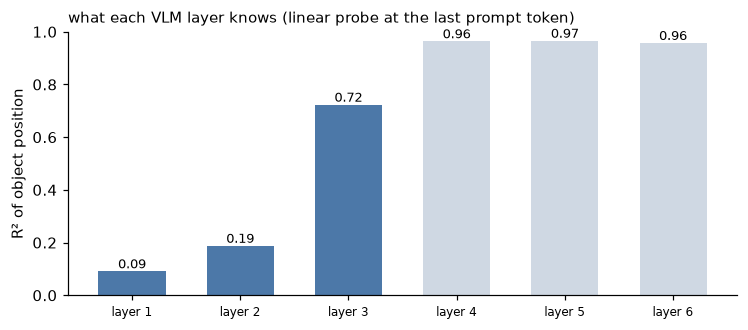

R² per layer: [0.09 0.19 0.72 0.96 0.97 0.96]


In [8]:
def probe_layers(vlm, n=2500, seed=1):
    rng = np.random.default_rng(seed)
    imgs, tx, ty, prompts = [], [], [], []
    for _ in range(n):
        scene = world.sample_scene(rng, 2)
        c = str(rng.choice(list(scene.objects)))
        imgs.append(world.render(scene.robot, scene.objects)); prompts.append(f"where is {c}")
        tx.append(scene.objects[c][0]); ty.append(scene.objects[c][1])
    imgs = torch.from_numpy(np.stack(imgs)); y = np.stack([tx, ty], 1)
    with torch.no_grad():
        inp = vlm.build_inputs(imgs, prompts)
        hs = vlm.forward_layers(inp)
        last = torch.tensor([e - 1 for _, e in inp.prompt_slices])
        feats = [h[torch.arange(n), last].numpy() for h in hs]
    split = int(0.8 * n)
    out = []
    for f in feats:
        A = np.c_[f, np.ones(n)]; lam = 1e-2 * np.eye(A.shape[1])
        coef = np.linalg.solve(A[:split].T @ A[:split] + lam, A[:split].T @ y[:split])
        pred = A[split:] @ coef
        out.append(1 - ((y[split:] - pred) ** 2).sum() / ((y[split:] - y[split:].mean(0)) ** 2).sum())
    return out

r2 = probe_layers(vlm)
plots.bar_compare({f"layer {i + 1}": v for i, v in enumerate(r2)}, "R² of object position", "what each VLM layer knows (linear probe at the last prompt token)", ylim=(0, 1.0), colors=["#4c78a8" if i < 3 else "#cfd8e3" for i in range(6)])
print("R² per layer:", np.round(r2, 2))

**Reading the probe.** The first two layers know almost nothing about *where* things are (they hold local patch features); the location emerges around **layer 3** (R² ≈ 0.7) and is essentially
complete by layer 4 (≈ 0.96), after which deeper layers add little. So keeping the first `N = L/2 = 3` layers keeps the layer where the information appears, while keeping `N = 1` would leave the expert
with nothing but raw patch features (Step 10 confirms it fails). The expert also does not read *one* layer: its cross-attention blocks read layers `1, 2, …, N`, one each. Now the actual savings of keeping
`N` of `L = 6` layers:

N = 6:   5.8 ms per VLM pass, 285,376 VLM parameters
N = 3:   4.2 ms per VLM pass, 162,112 VLM parameters
N = 1:   3.1 ms per VLM pass, 79,936 VLM parameters


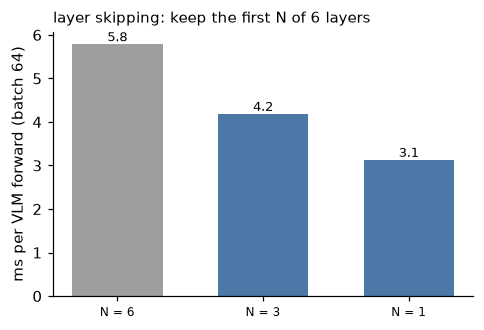

In [9]:
x = torch.rand(64, 3, 32, 32)
rows = {}
for n_keep in (6, 3, 1):
    v = copy.deepcopy(vlm).truncate(n_keep).eval()
    with torch.no_grad():
        v.forward_layers(v.build_inputs(x, ["go to red"] * 64)); t0 = time.perf_counter()
        for _ in range(15):
            v.forward_layers(v.build_inputs(x, ["go to red"] * 64))
    rows[f"N = {n_keep}"] = (1000 * (time.perf_counter() - t0) / 15, sum(p.numel() for p in v.parameters()))
for k, (ms, n) in rows.items():
    print(f"{k}: {ms:5.1f} ms per VLM pass, {n:,} VLM parameters")
plots.bar_compare({k: v[0] for k, v in rows.items()}, "ms per VLM forward (batch 64)", "layer skipping: keep the first N of 6 layers", fmt="{:.1f}", colors=["#9e9e9e", "#4c78a8", "#4c78a8"])

## Step 5: The action expert: thin, and *interleaved*

The expert `v_θ` is a small transformer that maps a noisy action chunk to a velocity. Four design choices, each visible in the code:

* **Width `0.75 × d`**. Smaller than the VLM, so it is cheap to run at every denoising step (paper Table 9: shrinking it to 0.25× hurts, 0.75-1.0× are close).
* **Time enters through the action tokens** with the π0-style MLP `W3 · swish(W2 · [W1·a^τ , φ(τ)])`: the noisy action and a sinusoidal embedding of the flow time `τ` are fused per token.
* **One expert block per kept VLM layer, alternating attention types.** Even blocks are **causal self-attention** among the action tokens (smooth chunks: each action sees the earlier ones),
  odd blocks are **cross-attention** whose keys and values are the VLM's hidden state **of the matching layer**, adapted to the expert's width by the block's own `k`/`v` projections
  ("feature projectors"). Other VLAs use only one kind: π0 puts VLM tokens and action tokens in *one* self-attention (`joint` below), GR00T uses only cross-attention.
* **Causal, not bidirectional, self-attention** over actions: it prevents action `i` from depending on a *future* action `j > i` (paper Table 7).

In [10]:
cfg = SmolVLAConfig()
model = SmolVLAPolicy(vlm, cfg)
print("blocks:", cfg.block_kinds(), "| expert width", cfg.expert_width, "(= 0.75 × VLM width", f"{cfg.vlm.width})")
print({k: f"{v:,}" for k, v in model.parameter_counts().items()})
print(model.blocks[1])

blocks: ['self', 'cross', 'self'] | expert width 48 (= 0.75 × VLM width 64)
{'total': '241,314', 'trainable': '79,202', 'vlm': '162,112', 'expert': '78,194'}
ExpertBlock(
  (attn_norm): RMSNorm()
  (mlp_norm): RMSNorm()
  (attn): Attention(
    (q): Linear(in_features=48, out_features=48, bias=False)
    (k): Linear(in_features=64, out_features=48, bias=False)
    (v): Linear(in_features=64, out_features=48, bias=False)
    (o): Linear(in_features=48, out_features=48, bias=False)
  )
  (mlp): SwiGLU(
    (gate): Linear(in_features=48, out_features=96, bias=False)
    (up): Linear(in_features=48, out_features=96, bias=False)
    (down): Linear(in_features=96, out_features=48, bias=False)
  )
)


**Check 1: the cross-attention block really is "softmax(QKᵀ/√d)·V over the VLM features".** We recompute one cross-attention block by hand from its own weights and compare:

In [11]:
with torch.no_grad():
    ctx = model.encode(batch)
    block = model.blocks[1]                                  # a cross-attention block, reads the VLM's layer-2 features
    x = torch.randn(batch.size, 16, cfg.expert_width)
    h = block.attn_norm(x)
    out_module = block.attn(h, ctx.features[1], ctx.feature_mask)
    att = block.attn
    q = att.q(h).view(batch.size, 16, att.num_heads, att.head_dim).transpose(1, 2)
    kk = att.k(ctx.features[1]).view(batch.size, -1, att.num_heads, att.head_dim).transpose(1, 2)
    vv = att.v(ctx.features[1]).view(batch.size, -1, att.num_heads, att.head_dim).transpose(1, 2)
    scores = (q @ kk.transpose(-1, -2) / att.head_dim ** 0.5).masked_fill(~ctx.feature_mask, float("-inf"))
    out_manual = att.o((scores.softmax(-1) @ vv).transpose(1, 2).reshape(batch.size, 16, -1))
print("by-hand cross-attention == module:", torch.allclose(out_module, out_manual, atol=1e-5))
print("keys/values come from the VLM:", tuple(ctx.features[1].shape), "= (B, tokens, VLM width) → projected to", tuple(kk.shape), "= (B, heads, tokens, head dim)")

by-hand cross-attention == module: True
keys/values come from the VLM: (6, 22, 64) = (B, tokens, VLM width) → projected to (6, 4, 22, 12) = (B, heads, tokens, head dim)


**Check 2: causality.** If we change the *last* eight noisy actions, the velocities predicted for the *first* eight must not move (the self-attention blocks are causal and the
cross-attention blocks only read the VLM):

max change of the first 8 outputs: 0.0    of the last 8: 0.0026724785566329956


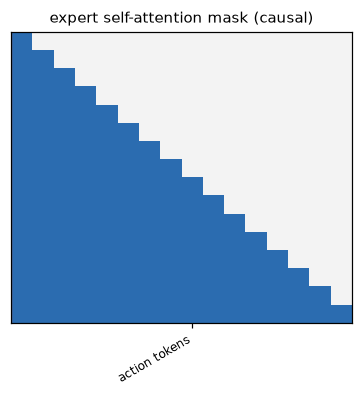

In [12]:
with torch.no_grad():
    noisy, tau = torch.randn(batch.size, 16, 2), torch.rand(batch.size)
    base = model.velocity(ctx, noisy, tau)
    perturbed = noisy.clone(); perturbed[:, 8:] += 1.0
    moved = model.velocity(ctx, perturbed, tau)
print("max change of the first 8 outputs:", float((moved[:, :8] - base[:, :8]).abs().max()), "   of the last 8:", float((moved[:, 8:] - base[:, 8:]).abs().max()))
plots.plot_mask(causal_mask(16), [("action tokens", 0, 16)], title="expert self-attention mask (causal)", size=3.4)

## Step 6: Flow matching, with a frozen VLM

The loss is conditional flow matching on the action chunk. With `A` the demonstrated chunk and `ε ~ N(0, I)`, the expert regresses the velocity of a straight path from data to noise:

$$A^\tau = \tau\,\varepsilon + (1-\tau)\,A,\qquad u = \varepsilon - A,\qquad \mathcal{L} = \mathbb{E}\,\big\|v_\theta(A^\tau, \tau \mid o) - u\big\|^2,\qquad \tau \sim \text{Beta}(1.5, 1)$$

(The paper's equation writes the interpolation the other way round, but, like LeRobot's code and π0, its implementation has **τ = 1 at noise**; `GR00T` in the next notebook uses
the mirrored convention. Same method under `τ ↔ 1 − τ`.) Sampling integrates the learned field from noise to data with 10 Euler steps; the **VLM runs once** and its features are reused
by every step.

**Only the expert trains.** The VLM is frozen (`requires_grad = False`), plus the small state and feature projectors. The state token *does* go through the frozen VLM, so gradients flow
*through* its layers to the state projection without ever updating them.

trainable 79,202 of 241,314 parameters (33 %), frozen VLM 162,112


step   750  loss 0.0723  (flow 0.072)


step  1500  loss 0.0517  (flow 0.052)


step  2250  loss 0.0487  (flow 0.049)


step  3000  loss 0.0474  (flow 0.047)
trained in 66 s


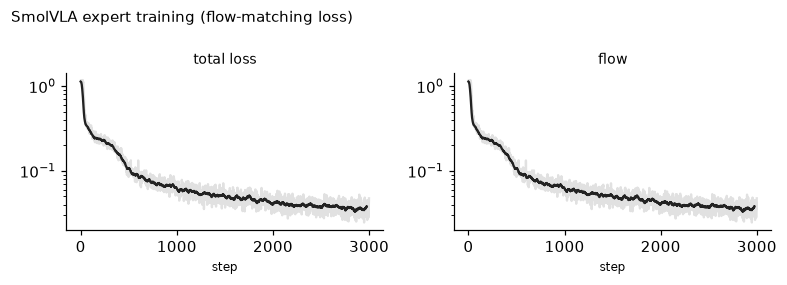

In [13]:
torch.manual_seed(0)
model = SmolVLAPolicy(vlm, SmolVLAConfig())
counts = model.parameter_counts()
print(f"trainable {counts['trainable']:,} of {counts['total']:,} parameters ({100 * counts['trainable'] / counts['total']:.0f} %), frozen VLM {counts['vlm']:,}")
trainer = PiTrainer(model, data, batch_size=64, lr=2e-3, grad_clip=10.0)
history = trainer.fit(3000, log_every=750)
print(f"trained in {history.seconds:.0f} s")
plots.plot_loss(history, keys=("flow",), title="SmolVLA expert training (flow-matching loss)")

## Step 7: Watch a chunk being denoised

The chunk after `k` of the 10 Euler steps, drawn as the path it would make the robot follow. Step 0 is noise; the expert, reading the (once-computed) VLM features, straightens it into a
reach for the instructed object.

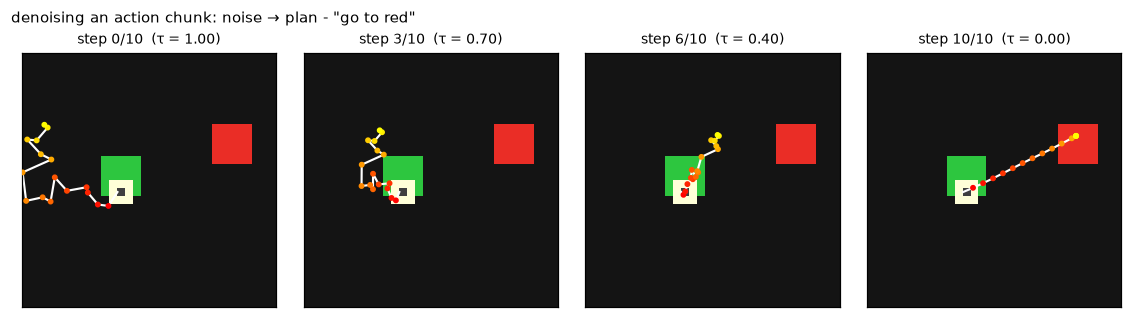

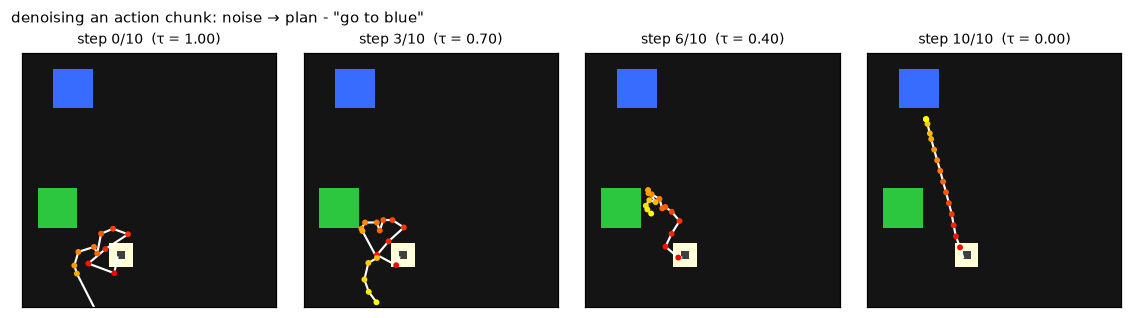

In [14]:
test_demos = make_reach_demos(gen, 200, np.random.default_rng(99))
test_batch = EmbodiedMixture([EmbodiedSource(world, test_demos, EMBODIMENTS["point2d"])]).sample(8, np.random.default_rng(3))
_, traj = model.sample_actions(test_batch, return_trajectory=True)
plots.plot_denoising(test_batch, traj, example=0, steps_to_show=[0, 3, 6, 10])
plots.plot_denoising(test_batch, traj, example=1, steps_to_show=[0, 3, 6, 10])

## Step 8: Where does the expert look? 🔬

The cross-attention weights tell us *what in the VLM's output the action tokens read*. For a trained model we expect the expert to look at the cell of the **instructed** object, not the
distractor. The VLM's 16 image tokens form a 4×4 grid over the 32×32 image (each token covers 8×8 pixels); we overlay the attention of the first and last action token of the chunk
(averaged over heads) on the image, for the last cross-attention block.

cross attention weights: (64, 4, 16, 22) = (B, heads, action tokens, VLM tokens)


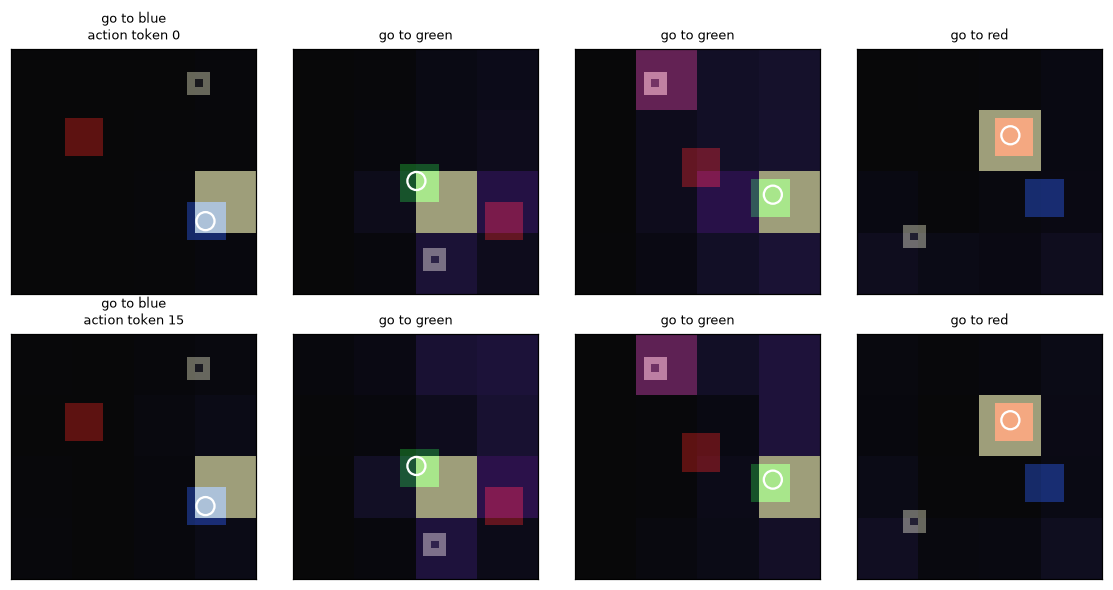

In [15]:
scen = make_embodied_scenarios(gen, "point2d", 64, seed=7)
ev = EmbodiedEvaluator(world, 16, 8, 50)
obs = ev.observe(scen, np.stack([s.scene.robot[None] for s in scen]).repeat(2, 1), np.full(len(scen), -1.0), 0)
with torch.no_grad():
    ctx = model.encode(obs)
    _, weights = model.velocity(ctx, torch.randn(len(scen), 16, 2), torch.full((len(scen),), 0.5), return_weights=True)
kind, w = [(k, w) for k, w in weights if k == "cross"][-1]                  # last cross-attention block
print(kind, "attention weights:", tuple(w.shape), "= (B, heads, action tokens, VLM tokens)")
targets = [(s.scene.objects[s.target][0] * 31, s.scene.objects[s.target][1] * 31) for s in scen]
plots.plot_cross_attention(obs.images, w, ctx.num_image_tokens, rows=(0, 15), titles=[s.task for s in scen], targets=targets)

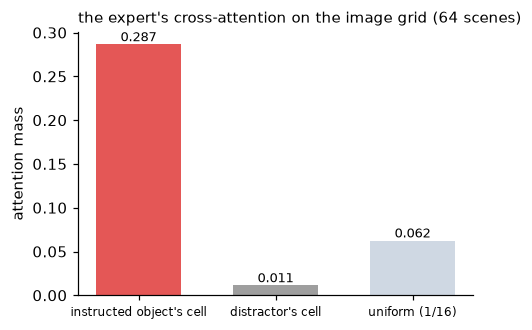

In [16]:
def cell(xy):                                  # which of the 4x4 image-token cells contains this pixel position
    col, row = int(min(xy[0] // 8, 3)), int(min(xy[1] // 8, 3)); return row * 4 + col
mass_t, mass_d = [], []
for i, s in enumerate(scen):
    a = w[i].mean(0).mean(0)[:16].numpy()            # attention over the 16 image tokens, averaged over heads and action tokens
    other = [c for c in s.scene.objects if c != s.target][0]
    mass_t.append(a[cell(targets[i])]); mass_d.append(a[cell((s.scene.objects[other][0] * 31, s.scene.objects[other][1] * 31))])
plots.bar_compare({"instructed object's cell": float(np.mean(mass_t)), "distractor's cell": float(np.mean(mass_d)), "uniform (1/16)": 1 / 16},
                  "attention mass", "the expert's cross-attention on the image grid (64 scenes)", fmt="{:.3f}", colors=["#e45756", "#9e9e9e", "#cfd8e3"])

**Reading the figure.** The bright cells sit on the object the instruction names, and much more of the attention lands there than on the distractor. Nobody told the expert to attend the target:
it learned that doing so is what lowers the flow-matching loss. Together with Step 4's probe this is the full story of SmolVLA's perception: *the VLM turns "the red thing" into features at
the right place; the expert learns to read exactly those features.*

## Step 9: Closed loop, and the controls

Closed loop: the robot starts somewhere new, the model predicts a chunk, the first 8 actions run, then it looks again. 96 unseen scenes; success = touching the instructed object within 50 steps.

closed loop: {'success': 0.979, 'steps': 13.1, 'path': 0.5, 'wrong_first': 0.01} | 2.0 ms per scene


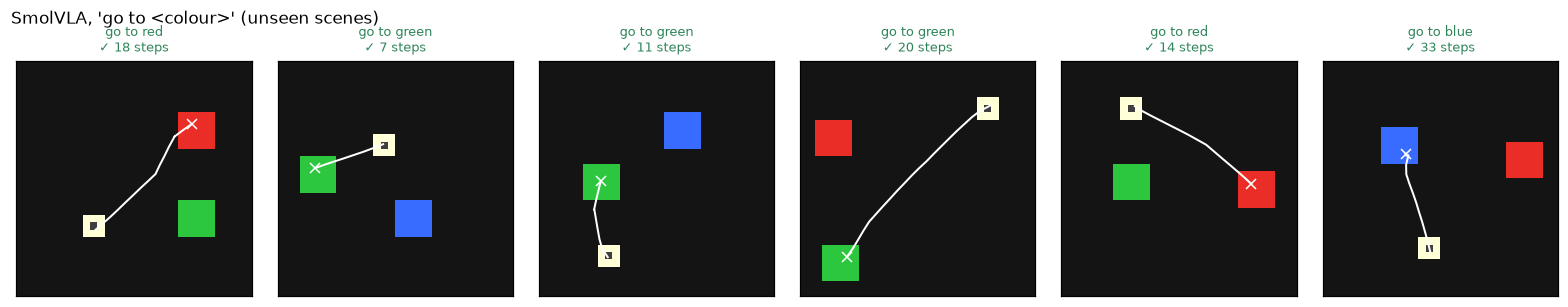

In [17]:
ev = EmbodiedEvaluator(world, 16, 8, 50)
scen = make_embodied_scenarios(gen, "point2d", 96, seed=123)
t0 = time.perf_counter(); res = ev.run(lambda b: model.sample_actions(b), scen); dt = time.perf_counter() - t0
print("closed loop:", res.summary(), f"| {1000 * dt / len(scen):.1f} ms per scene")
plots.plot_rollouts(res, scen, world, title="SmolVLA, 'go to <colour>' (unseen scenes)")

In [18]:
import copy
swapped = []
for s in scen:
    other = [c for c in s.scene.objects if c != s.target][0]
    s2 = copy.copy(s); s2.task, s2.target = f"go to {other}", other
    swapped.append(s2)
blind = ev.run(lambda b: model.sample_actions(b.replace(images=torch.zeros_like(b.images))), scen)
sw = ev.run(lambda b: model.sample_actions(b), swapped)
print(f"normal {res.success_rate:.2f} | swapped colour word (success measured on the NEW target) {sw.success_rate:.2f} | black image {blind.success_rate:.2f}")

normal 0.98 | swapped colour word (success measured on the NEW target) 0.97 | black image 0.03


The model follows the *language* (swapping the colour word sends it to the other object) and depends on the *image* (a black image collapses success): both halves of the VLM's job.

## Step 10: The paper's ablations, on our toy

The SmolVLA paper justifies each design choice with a LIBERO ablation. We rerun the same questions here, **each variant trained from the same pre-trained VLM for 3000 steps**
(about a minute each). A single seed means small gaps are noise.

| question | paper's finding (LIBERO) | variants here |
|---|---|---|
| how many VLM layers? (Tab. 8) | `N = L/2` is a good trade-off; keeping 8 of 32 is clearly worse | `N = 1, 3, 6` |
| cross-attention vs self-attention vs both? (Tab. 6) | interleaved CA+SA best (85.5), CA 79.0, SA 74.5 | `interleaved`, `cross`, `joint` |
| causal vs bidirectional action self-attention? (Tab. 7) | causal 74.5 vs bidirectional 67.5 | `causal`, `bidirectional` |
| state to the VLM or the expert? (Tab. 11) | prefix (VLM) 80.3 vs suffix 73.3 | `prefix`, `suffix` |
| expert width? (Tab. 9) | 0.75× a good balance; 0.25× hurts | `0.5×`, `0.75×`, `1.0×` |

In [19]:
variants = {
    "N=3 · interleaved · causal · prefix · 0.75×": {},
    "N=6 (no skipping)": dict(skip_to=6),
    "N=1": dict(skip_to=1),
    "all cross-attention": dict(layout="cross"),
    "joint SA (π0-style)": dict(layout="joint"),
    "bidirectional SA": dict(self_attention="bidirectional"),
    "state in suffix": dict(state_in="suffix"),
    "expert 0.5×": dict(expert_ratio=0.5),
    "expert 1.0×": dict(expert_ratio=1.0),
}
ablation = {}
eval96 = make_embodied_scenarios(gen, "point2d", 96, seed=123)
for name, kw in variants.items():
    if not kw:
        m, hist = model, history                              # reuse the model trained in Step 6
    else:
        torch.manual_seed(0)
        m = SmolVLAPolicy(vlm, SmolVLAConfig(**kw))
        hist = PiTrainer(m, data, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000)
    r = ev.run(lambda b: m.sample_actions(b), eval96)
    xb = data.sample(64, np.random.default_rng(0))
    m.sample_actions(xb); t0 = time.perf_counter()
    for _ in range(5):
        m.sample_actions(xb)
    ablation[name] = dict(success=r.success_rate, steps=r.summary()["steps"], trainable=m.parameter_counts()["trainable"], ms=1000 * (time.perf_counter() - t0) / 5, flow=float(np.mean(hist.series("flow")[-100:])))
    print(f"{name:44s} success {r.success_rate:.2f} | trainable {ablation[name]['trainable']:7,} | {ablation[name]['ms']:5.1f} ms/chunk (batch 64) | final flow loss {ablation[name]['flow']:.3f}", flush=True)

N=3 · interleaved · causal · prefix · 0.75×  success 0.92 | trainable  79,202 |  18.6 ms/chunk (batch 64) | final flow loss 0.036


N=6 (no skipping)                            success 0.98 | trainable 151,682 |  36.0 ms/chunk (batch 64) | final flow loss 0.033


N=1                                          success 0.04 | trainable  31,394 |  10.5 ms/chunk (batch 64) | final flow loss 0.246


all cross-attention                          success 0.98 | trainable  82,274 |  21.0 ms/chunk (batch 64) | final flow loss 0.039


joint SA (π0-style)                          success 0.89 | trainable  87,026 |  27.7 ms/chunk (batch 64) | final flow loss 0.044


bidirectional SA                             success 0.95 | trainable  79,202 |  20.2 ms/chunk (batch 64) | final flow loss 0.035


state in suffix                              success 0.97 | trainable  79,154 |  21.1 ms/chunk (batch 64) | final flow loss 0.031


expert 0.5×                                  success 0.96 | trainable  36,994 |  15.6 ms/chunk (batch 64) | final flow loss 0.038


expert 1.0×                                  success 0.95 | trainable 137,282 |  22.1 ms/chunk (batch 64) | final flow loss 0.035


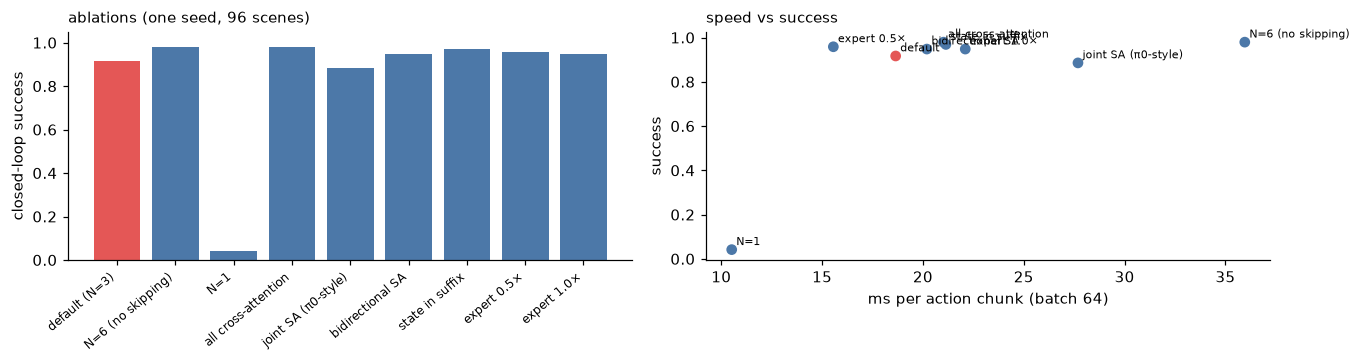

In [20]:
names = list(ablation)
short = [n.split(" ·")[0] if n.startswith("N=3") else n for n in names]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.4), facecolor="white")
axes[0].bar(range(len(names)), [ablation[n]["success"] for n in names], color=["#e45756"] + ["#4c78a8"] * (len(names) - 1))
axes[0].set_xticks(range(len(names))); axes[0].set_xticklabels(["default (N=3)"] + short[1:], rotation=40, ha="right", fontsize=8)
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("closed-loop success"); axes[0].set_title("ablations (one seed, 96 scenes)", fontsize=10, loc="left")
axes[1].scatter([ablation[n]["ms"] for n in names], [ablation[n]["success"] for n in names], c=["#e45756"] + ["#4c78a8"] * (len(names) - 1))
for n, s in zip(names, ["default"] + short[1:]):
    axes[1].annotate(s, (ablation[n]["ms"], ablation[n]["success"]), fontsize=7.5, xytext=(3, 3), textcoords="offset points")
axes[1].set_xlabel("ms per action chunk (batch 64)"); axes[1].set_ylabel("success"); axes[1].set_title("speed vs success", fontsize=10, loc="left")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**What to take from this** (read it against the paper's tables, with the one-seed caveat; the success numbers are for 96 scenes, so gaps of ~5 points are noise):

* *Layer skipping.* `N = 1` **fails** (the probe in Step 4 explained why: layer 1 knows nothing about location). `N = 3` (half) is already accurate and takes about **half the time per chunk** of `N = 6`; keeping all six layers
  is not worse here but is slower and needs twice the expert blocks: the paper's "N = L/2 is a good trade-off", and (like the paper) cutting too deep is what breaks.
* *Attention type.* The paper's best layout is the interleaved one, but on this tiny task **cross-attention alone is as good or better** (everything the expert needs is in the VLM features and there is
  one object to find); the π0-style joint self-attention is the slowest to train. The interleaving's job in the paper is *smoothness* of chunks on real robots, which our noiseless point robot does not stress.
* *Causal vs bidirectional*, *state placement* and *expert width* all land within seed noise of each other here (even the 0.5× expert is enough for this task); the paper's rankings come from LIBERO's far
  harder, longer-horizon tasks. Do not read a ranking into the small differences.

## Step 11: Asynchronous inference

Everything so far was **synchronous**: predict a chunk of `n` actions, execute all of them, observe, predict again. Two things go wrong on a real robot:

1. while the model computes (latency `ℓ`) the robot **sits idle**;
2. for `n` steps the robot is **open-loop**: it cannot react to anything.

SmolVLA's fix is an **asynchronous inference stack** (Algorithm 1 of the paper): a *RobotClient* with an action queue, a (possibly remote) *PolicyServer*.

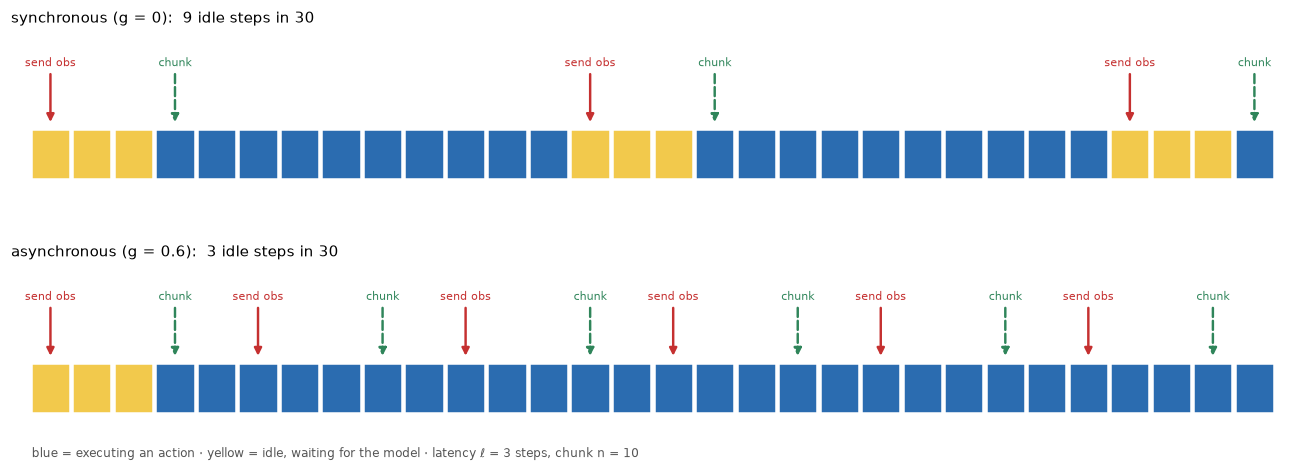

In [21]:
dg.fig_async_timeline(chunk=10, latency=3, g=0.6)

The client pops one action per control step. When the queue shrinks below a **threshold** `|A_t| / n < g` it captures an observation and sends it to the server **while it keeps executing the old
queue**. The chunk comes back `ℓ` steps later (inference + network); the first part of it describes steps that have already been executed from the old queue, so it is **dropped**, and the rest is
**aggregated** into the queue (new wins, old wins, or average, on the overlap). An **observation-similarity filter** skips queries whose joint-space state is within `ε` of the last one sent, unless
the queue is empty. The knob `g` spans three regimes:

| `g` | regime | idle time | model calls |
|---|---|---|---|
| 0 | **sequential / synchronous**: query only when the queue is empty | `ℓ` steps per chunk | fewest |
| ∈ (0, 1) | **asynchronous**: the queue never empties if `g ≥ ℓ / n` | none (after the first chunk) | in between |
| 1 | **compute-intensive**: a query at every step (as in ACT / Diffusion Policy) | none | one per control step |

To make time matter we need tasks longer than one chunk, so this section uses a **slower robot** (steps 2.5× smaller: a reach takes about 30 steps instead of 12) and trains a fresh expert on it
(same pre-trained VLM).

In [22]:
slow_world = PointWorld(max_step=0.02)
slow_gen = DemoGenerator(slow_world)
slow_demos = make_reach_demos(slow_gen, 4000, np.random.default_rng(0))
slow_data = EmbodiedMixture([EmbodiedSource(slow_world, slow_demos, EMBODIMENTS["point2d"])])
print("mean demonstration length:", np.mean([d.active_steps for d in slow_demos]).round(1), "steps (chunk n = 16)")
torch.manual_seed(0)
slow_model = SmolVLAPolicy(vlm, SmolVLAConfig())
sh = PiTrainer(slow_model, slow_data, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000)
print(f"trained in {sh.seconds:.0f} s")
slow_scen = make_embodied_scenarios(slow_gen, "point2d", 40, seed=11)
policy_call = make_policy_call(slow_model)
sync_res = EmbodiedEvaluator(slow_world, 16, 16, 100).run(lambda b: slow_model.sample_actions(b), slow_scen)
print("(for reference) the synchronous evaluator with the whole chunk executed:", sync_res.summary())

mean demonstration length: 28.4 steps (chunk n = 16)


trained in 74 s
(for reference) the synchronous evaluator with the whole chunk executed: {'success': 0.95, 'steps': 28.2, 'path': 0.459, 'wrong_first': 0.025}


### Queue evolution (paper Fig. 3)

One scenario, three values of `g`, inference latency `ℓ = 4` control steps. Yellow = the robot is idle (queue empty), red dotted lines = an observation was sent.

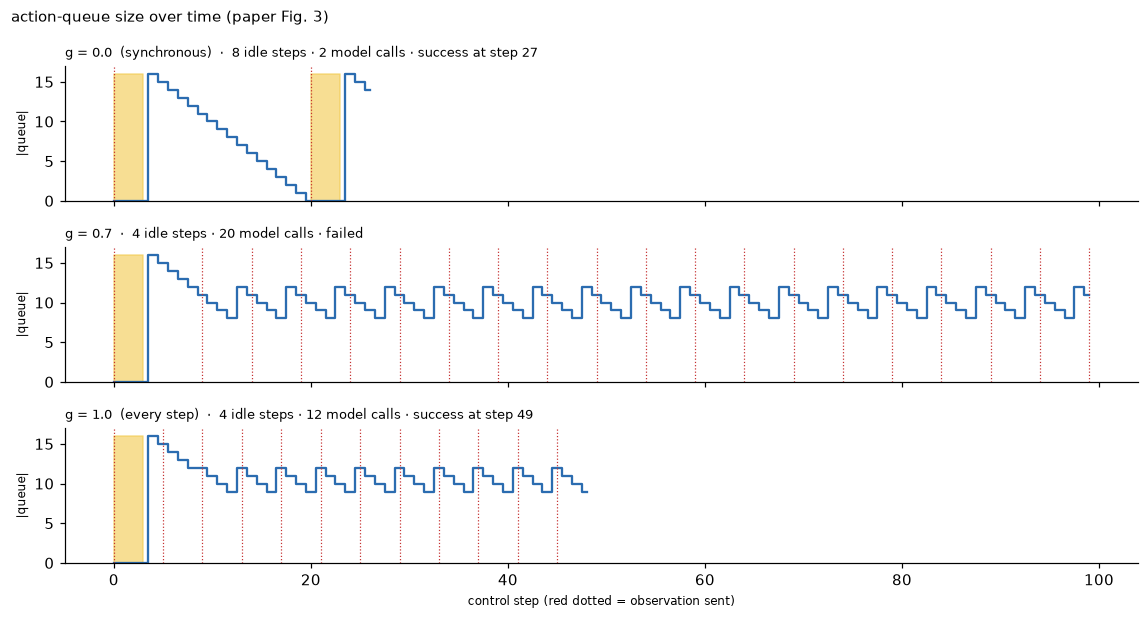

In [23]:
s0 = slow_scen[2]
traces = {}
for g in (0.0, 0.7, 1.0):
    runner = AsyncInferenceRunner(slow_world, policy_call, AsyncConfig(threshold=g, latency=4, max_steps=100), rng=np.random.default_rng(0))
    traces[f"g = {g}" + ("  (synchronous)" if g == 0 else "  (every step)" if g == 1 else "")] = runner.run(s0.scene, s0.task, s0.target)
plots.plot_queue_traces(traces, chunk_size=16)

### Sync vs async over many scenes

Same trained model, `ℓ = 4`. `steps` is the time to success *including idle steps*; `calls` is the number of model queries per episode (the compute cost). In the second block random pushes
(30 % chance per step, up to 0.06) displace the robot: a reactive stack should recover faster.

no disturbances:


g = 0.0   success 0.90   steps  38.0   idle 10.6   model calls  2.6


g = 0.3   success 0.90   steps  30.7   idle  4.0   model calls  3.1


g = 0.7   success 0.90   steps  32.4   idle  4.0   model calls  7.5


g = 1.0   success 0.85   steps  31.6   idle  4.0   model calls 10.6
with pushes:


g = 0.0   success 0.82   steps  49.9   idle 13.1   model calls  3.3


g = 0.3   success 0.78   steps  38.3   idle  4.0   model calls  4.4


g = 0.7   success 0.93   steps  36.2   idle  4.0   model calls  8.0


g = 1.0   success 0.88   steps  38.7   idle  4.0   model calls 11.8


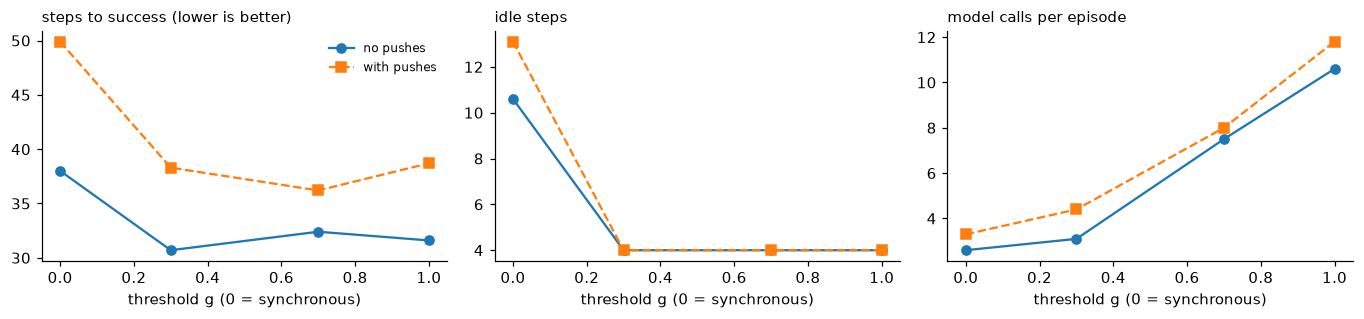

In [24]:
def table(**kw):
    rows = {}
    for g in (0.0, 0.3, 0.7, 1.0):
        out = evaluate_async(slow_world, policy_call, AsyncConfig(threshold=g, latency=4, max_steps=100, **kw), slow_scen, seed=3)
        rows[g] = {k: v for k, v in out.items() if k != "traces"}
        print(f"g = {g:3.1f}   success {out['success']:.2f}   steps {out['steps']:5.1f}   idle {out['idle']:4.1f}   model calls {out['calls']:4.1f}")
    return rows

print("no disturbances:"); calm = table()
print("with pushes:"); pushed = table(push_prob=0.3, push_size=0.06)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.0), facecolor="white")
for ax, (key, label) in zip(axes, (("steps", "steps to success (lower is better)"), ("idle", "idle steps"), ("calls", "model calls per episode"))):
    ax.plot(list(calm), [v[key] for v in calm.values()], "o-", label="no pushes"); ax.plot(list(pushed), [v[key] for v in pushed.values()], "s--", label="with pushes")
    ax.set_xlabel("threshold g (0 = synchronous)"); ax.set_title(label, fontsize=9.5, loc="left"); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

**Reading the numbers.** Going from `g = 0` to any `g ≥ ℓ/n = 0.25` removes the idle gaps after the first chunk (the first wait is unavoidable: there is no old queue yet), so the task finishes sooner,
the effect the paper reports as ~30 % faster on real pick-and-place (9.7 s vs 13.75 s) and 19 vs 9 cubes in a fixed time. The cost is more model calls: `g = 1` queries at every step. With pushes, the
asynchronous stack's shorter observation-to-action loop corrects the robot sooner.

### The levers of the stack: latency, similarity filter, aggregation

Three knobs we have not touched. **Latency**: how much does a slower server hurt each regime? **Similarity filter**: how many redundant queries can we skip? **Aggregation**: what to do where
the old queue and the new chunk overlap?

latency ℓ (control steps) → time to success, synchronous vs asynchronous (g = 0.7):


  ℓ = 0: sync  30.4 steps (idle  0.0) | async  27.3 steps (idle  0.0)


  ℓ = 2: sync  33.7 steps (idle  5.5) | async  29.9 steps (idle  2.0)


  ℓ = 4: sync  35.7 steps (idle 10.0) | async  31.4 steps (idle  4.0)


  ℓ = 8: sync  47.0 steps (idle 20.4) | async  33.2 steps (idle  8.0)


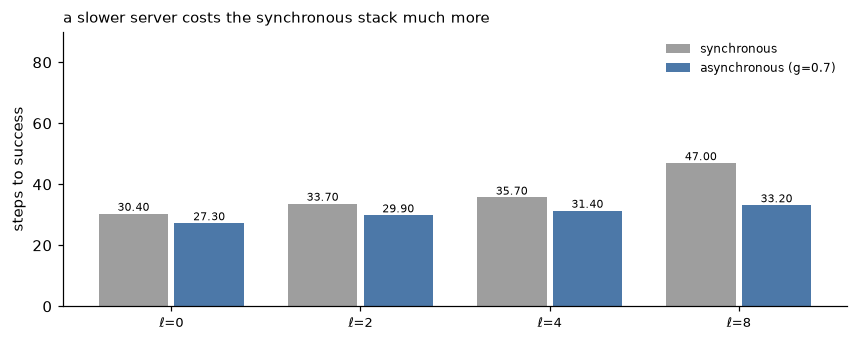

In [25]:
print("latency ℓ (control steps) → time to success, synchronous vs asynchronous (g = 0.7):")
lat_rows = {}
for lat in (0, 2, 4, 8):
    a = evaluate_async(slow_world, policy_call, AsyncConfig(threshold=0.0, latency=lat, max_steps=100), slow_scen, seed=3)
    b = evaluate_async(slow_world, policy_call, AsyncConfig(threshold=0.7, latency=lat, max_steps=100), slow_scen, seed=3)
    lat_rows[f"ℓ={lat}"] = {"synchronous": a["steps"], "asynchronous (g=0.7)": b["steps"]}
    print(f"  ℓ = {lat}: sync {a['steps']:5.1f} steps (idle {a['idle']:4.1f}) | async {b['steps']:5.1f} steps (idle {b['idle']:4.1f})")
plots.grouped_bars(lat_rows, "steps to success", "a slower server costs the synchronous stack much more", ylim=(0, 90), colors=["#9e9e9e", "#4c78a8"])

In [26]:
print("similarity filter ε (g = 1, ℓ = 4): skipping near-duplicate observations")
for eps in (0.0, 0.03, 0.08):
    out = evaluate_async(slow_world, policy_call, AsyncConfig(threshold=1.0, latency=4, max_steps=100, similarity_eps=eps), slow_scen, seed=3)
    print(f"  ε = {eps:4.2f}: success {out['success']:.2f}, steps {out['steps']:5.1f}, model calls {out['calls']:4.1f}")
print("\naggregation of overlapping chunks (g = 0.7, ℓ = 4, with pushes):")
for mode in ("replace", "average", "keep_old"):
    out = evaluate_async(slow_world, policy_call, AsyncConfig(threshold=0.7, latency=4, max_steps=100, aggregate=mode, push_prob=0.3, push_size=0.06), slow_scen, seed=3)
    print(f"  {mode:9s}: success {out['success']:.2f}, steps {out['steps']:5.1f}")

similarity filter ε (g = 1, ℓ = 4): skipping near-duplicate observations


  ε = 0.00: success 0.93, steps  33.2, model calls  9.7


  ε = 0.03: success 0.95, steps  32.8, model calls  7.6


  ε = 0.08: success 0.95, steps  33.8, model calls  5.7

aggregation of overlapping chunks (g = 0.7, ℓ = 4, with pushes):


  replace  : success 0.90, steps  44.6


  average  : success 0.88, steps  41.2


  keep_old : success 0.72, steps  37.8


The paper's analysis in one line: with control period `Δt` and expected server latency `E[ℓ_S]`, the queue is never exhausted for `g ≥ E[ℓ_S] / (Δt · n)`. Here `ℓ = 4`, `n = 16`, so `g ≥ 0.25`: and
indeed `g = 0.3` already has no idle steps beyond the first wait, while larger `g` only add model calls.

## Step 12: Recap and exercises

```
image ─► patch tokens ─► pixel shuffle (64 → 16 tokens) ┐
prompt words ───────────────────────────────────────────┼─► frozen VLM, layers 1…N (N = L/2) ──┬─ layer 1 features ─┐
state q_t ─► Linear ─► one token ───────────────────────┘                                      ├─ layer 2 features ─┤  (kept per layer)
noise ε, τ ─► action-time MLP ─► action tokens ─► [ SA (causal) ─ CA ─ SA ─ CA … ] ◄──────────┴────────────────────┘ cross-attention
                                                  │   thin expert, 0.75× width                                      flow matching, 10 Euler steps
                                                  ▼
                                      action chunk ─► RobotClient queue ◄─── threshold g, latency ℓ, similarity filter ε, aggregation
```

**What SmolVLA shows:** a pretrained, frozen, *half-depth* VLM plus a small expert that cross-attends the right layers is enough to follow instructions and act; and a model-agnostic
asynchronous stack removes the idle time of chunked policies. **What our toy cannot show:** transfer across robots, the community-data pre-training (the paper's headline), or noisy real-world
chunks (where the interleaved self-attention's smoothing matters).

### 🧪 Exercises
1. Set `skip_to=2` and plot the cross-attention maps of Step 8: which VLM layer do the action tokens rely on?
2. Train the expert with `objective="regression"` (L1) and compare with flow matching on a *multimodal* task (see `pi0_step_by_step.ipynb`, Step 11): the paper's Table 10 says flow matching wins.
3. Give the server a **random** latency (ℓ ∈ {2…8}) in `AsyncConfig`-driven runs: how does the choice of `g` interact with the latency *variance*?
4. Add a second moving object to `PointWorld` so that the target moves while the model thinks: when does `g = 1` beat `g = 0.7`?
5. Increase the chunk length to 32 in `SmolVLAConfig` (paper Table 12: n between 10 and 50 is a good range; n = 1 or 100 is not) and re-run Step 9.